In [62]:
import numpy as np
import matplotlib.pyplot as plt
import sunpy 
import sunpy.map
from sunpy.coordinates import propagate_with_solar_surface, get_earth
from scipy.io import readsav
from glob import glob 
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
from fancy_colorbar import plot_colorbar
from tqdm.notebook import tqdm
from ndcube import NDCube
import os 
import sys 
sys.path.insert(0, "/cluster/home/zhuyin/scripts/EMToolKitPlus/")

from varying_tresp_dem import varying_tresp_dem
from spatial_reg_dem import spatial_reg_dem
from dem_visualization import rgb_composite, rgb_color_reference, plot_rgb_composite

import slit_interactive
from slit_interactive import (SlitPick, plot_slit_position,
        remove_background, generate_slit_data_from_points,
        generate_straight_slit_data)

In [2]:
aia_response = readsav("../../sav/aia_response_2022_10_24.sav")

In [43]:
logte = aia_response["interp_logte"][:-6]
resp_euv = aia_response["resp_euv"][:-6]

In [4]:
dkist_vbi_target_header = fits.getheader("../../data/pid_1_123_aux/plot_ready/dkist_target_wcs_header_before_crop.fits",
                                        ignore_missing_simple=True)

dkist_vbi_target_data = np.zeros((4096,4096))

dkist_vbi_target_cube = NDCube(dkist_vbi_target_data,WCS(dkist_vbi_target_header, naxis=2))
dkist_vbi_target_cube_crop = dkist_vbi_target_cube[128:-128,128:-128]

pixel_scale = dkist_vbi_target_header["CDELT1"]/3600*np.pi/180*get_earth(dkist_vbi_target_header["DATE-AVG"]).radius.to_value(u.Mm)

Set MJD-BEG to 59876.791095 from DATE-BEG.
Set MJD-AVG to 59876.791095 from DATE-AVG.
Set MJD-END to 59876.791095 from DATE-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    20.706700 from OBSGEO-[XYZ].
Set OBSGEO-H to     3063.997 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [5]:
aia_94_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/94/*.94.image.fits"))
aia_131_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/131/*.131.image.fits"))
aia_171_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/171/*.171.image.fits"))
aia_193_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/193/*.193.image.fits"))
aia_211_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/211/*.211.image.fits"))
aia_335_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/derot/335/*.335.image.fits"))

In [6]:
aia_94_maps = sunpy.map.Map(aia_94_files, sequence=True)
aia_131_maps = sunpy.map.Map(aia_131_files, sequence=True)
aia_171_maps = sunpy.map.Map(aia_171_files, sequence=True)
aia_193_maps = sunpy.map.Map(aia_193_files, sequence=True)
aia_211_maps = sunpy.map.Map(aia_211_files, sequence=True)
aia_335_maps = sunpy.map.Map(aia_335_files, sequence=True)

In [7]:
aia_94_array = aia_94_maps.data
aia_131_array = aia_131_maps.data
aia_171_array = aia_171_maps.data
aia_193_array = aia_193_maps.data
aia_211_array = aia_211_maps.data
aia_335_array = aia_335_maps.data

In [8]:
aia_94_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/94/*.94.image.fits"))
aia_131_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/131/*.131.image.fits"))
aia_171_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/171/*.171.image.fits"))
aia_193_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/193/*.193.image.fits"))
aia_211_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/211/*.211.image.fits"))
aia_335_files_raw = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/335/*.335.image.fits"))

In [9]:
aia_94_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_94_files_raw])
aia_131_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_131_files_raw])
aia_171_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_171_files_raw])
aia_193_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_193_files_raw])
aia_211_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_211_files_raw])
aia_335_exptime = np.array([fits.getheader(file, ext=1)["EXPTIME"] for file in aia_335_files_raw])

In [17]:
aia_exptime = np.array(
    [aia_94_exptime, aia_131_exptime, aia_171_exptime, aia_193_exptime, aia_211_exptime, aia_335_exptime]
)

In [10]:
x_select_df1  = np.array(
    [562.8, 512.5, 476.9, 427.0]
)*4

y_select_df1 = np.array(
    [459.5, 478.0, 486.0, 483.3]
)*4
#====================================================================================
x_select_df2 = np.array(
    [380, 336, 246]
)*4

y_select_df2 = np.array(
    [755, 775, 783]
)*4
#====================================================================================
x_select_df3 = np.array(
    [551.5, 533.4, 499.7,]
)*4

y_select_df3 = np.array(
    [626.0, 715.1, 882.8,]
)*4

#====================================================================================
x_select_df4 = np.array(
    [426, 350.6, 283.6]
)*4

y_select_df4 = np.array(
    [563.8, 535.9, 498.0]
)*4

#====================================================================================
x_select_ef1 = np.array(
    [396, 358, 322.4, 282, 242, 210, 178]
)*4

y_select_ef1 = np.array(
    [461, 433.5, 399, 346, 287, 232, 177]
)*4

#====================================================================================
x_select_ef2 = np.array(
    [459.8, 402.4, 337.7, 317.6]
)*4

y_select_ef2 = np.array(
    [375.1, 301.9, 207.0, 168.3]
)*4

In [11]:
def convert_to_aia(x, y, aia_wcs = aia_94_maps[0].wcs, dkist_wcs = dkist_vbi_target_cube_crop.wcs):
    with propagate_with_solar_surface():
        dkist_coord = dkist_wcs.pixel_to_world(x, y)
        aia_coord_x, aia_coord_y = aia_wcs.world_to_pixel(dkist_coord)
    return aia_coord_x, aia_coord_y

In [12]:
x_aia_df1, y_aia_df1 = convert_to_aia(x_select_df1, y_select_df1)
x_aia_df2, y_aia_df2 = convert_to_aia(x_select_df2, y_select_df2)
x_aia_df3, y_aia_df3 = convert_to_aia(x_select_df3, y_select_df3)
x_aia_df4, y_aia_df4 = convert_to_aia(x_select_df4, y_select_df4)
x_aia_ef1, y_aia_ef1 = convert_to_aia(x_select_ef1, y_select_ef1)
x_aia_ef2, y_aia_ef2 = convert_to_aia(x_select_ef2, y_select_ef2)

In [13]:
def estimate_aia_error(aia_array):
    refchannels = np.array(['AIA94_THIN', 'AIA131_THIN', 'AIA171_THIN', 
        'AIA193_THIN', 'AIA211_THIN', 'AIA335_THIN'])
    refg = np.array([2.128, 1.523, 1.168, 1.024, 0.946, 0.596])
    refn = np.array([1.14, 1.18, 1.15, 1.2, 1.2, 1.18])

    return np.sqrt(np.clip(aia_array * refg[np.newaxis, np.newaxis, :], 0.0, None) + \
                   refn[np.newaxis, np.newaxis, :] ** 2)

In [14]:
def get_slit_data(
    x_aia, y_aia,
    aia_94_array = aia_94_array,
    aia_131_array = aia_131_array,
    aia_171_array = aia_171_array,
    aia_193_array = aia_193_array,
    aia_211_array = aia_211_array,
    aia_335_array = aia_335_array,
    line_width=1
):
    slit_aia_94_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_94_array, "NDArray", line_width=line_width,
    )

    slit_aia_131_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_131_array, "NDArray", line_width=line_width,
    )

    slit_aia_171_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_171_array, "NDArray", line_width=line_width,
    )

    slit_aia_193_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_193_array, "NDArray", line_width=line_width,
    )

    slit_aia_211_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_211_array, "NDArray", line_width=line_width,
    )

    slit_aia_335_result = generate_slit_data_from_points(
        x_aia, y_aia, aia_335_array, "NDArray", line_width=line_width,
    )

    slit_aia_array = np.array([
        slit_aia_94_result["slit_intensity"],
        slit_aia_131_result["slit_intensity"],
        slit_aia_171_result["slit_intensity"],
        slit_aia_193_result["slit_intensity"],
        slit_aia_211_result["slit_intensity"],
        slit_aia_335_result["slit_intensity"],
    ]).transpose(1,2,0)

    slit_aia_error = estimate_aia_error(slit_aia_array)


    return slit_aia_array, slit_aia_error

In [26]:
aia_array_df1, aia_error_df1 = get_slit_data(x_aia_df1, y_aia_df1, line_width=2)
aia_array_df2, aia_error_df2 = get_slit_data(x_aia_df2, y_aia_df2, line_width=2)
aia_array_df3, aia_error_df3 = get_slit_data(x_aia_df3, y_aia_df3, line_width=2)
aia_array_df4, aia_error_df4 = get_slit_data(x_aia_df4, y_aia_df4, line_width=2)
aia_array_ef1, aia_error_ef1 = get_slit_data(x_aia_ef1, y_aia_ef1, line_width=2)
aia_array_ef2, aia_error_ef2 = get_slit_data(x_aia_ef2, y_aia_ef2, line_width=2)

In [50]:
aia_df1_dem, aia_df1_chi2, aia_df1_info = varying_tresp_dem(
            aia_array_df1,
            aia_error_df1,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
        )

aia_df2_dem, aia_df2_chi2, aia_df2_info = varying_tresp_dem(
            aia_array_df2,
            aia_error_df2,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
        )

aia_df3_dem, aia_df3_chi2, aia_df3_info = varying_tresp_dem(
            aia_array_df3,
            aia_error_df3,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
        )

aia_df4_dem, aia_df4_chi2, aia_df4_info = varying_tresp_dem(
            aia_array_df4,
            aia_error_df4,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
)

aia_ef1_dem, aia_ef1_chi2, aia_ef1_info = varying_tresp_dem(
            aia_array_ef1,
            aia_error_ef1,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
)

aia_ef2_dem, aia_ef2_chi2, aia_ef2_info = varying_tresp_dem(
            aia_array_ef2,
            aia_error_ef2,
            aia_exptime[:,0],
            logte,
            resp_euv,
            backend="numba"
)

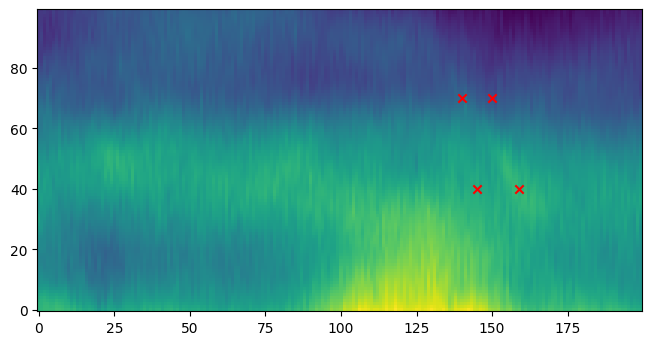

In [51]:
fig, ax = plt.subplots(layout="constrained")
ax.imshow(aia_array_ef1[:,:,2], origin="lower")
ax.scatter(140, 70, color="red", marker="x")
ax.scatter(150, 70, color="red", marker="x")

ax.scatter(159, 40, color="red", marker="x")
ax.scatter(145, 40, color="red", marker="x")

In [55]:
logte[6:14]

array([5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3], dtype='>f8')

In [63]:
def show_slit_dem(aia_dem):
    fig, axes = plt.subplots(2, 2, figsize=(8,4), layout='constrained', sharex=True, sharey=True)
    axes = axes.flatten()

    for ii, ax_ in zip(range(6,14,2), axes):
        dem_avg_ = np.nansum(aia_dem[:,:,ii:ii+2], axis=2)
        im_ = ax_.imshow(dem_avg_, origin="lower", interpolation="nearest", cmap="magma")
        ax_.set_title(rf"$\log T_e \in [{logte[ii]:.2f}, {logte[ii+1]:.2f}]$")

        clb_, clb_ax_ = plot_colorbar(im_, ax=ax_, bbox_to_anchor=(1.05, 0.1, 0.05, 0.9))

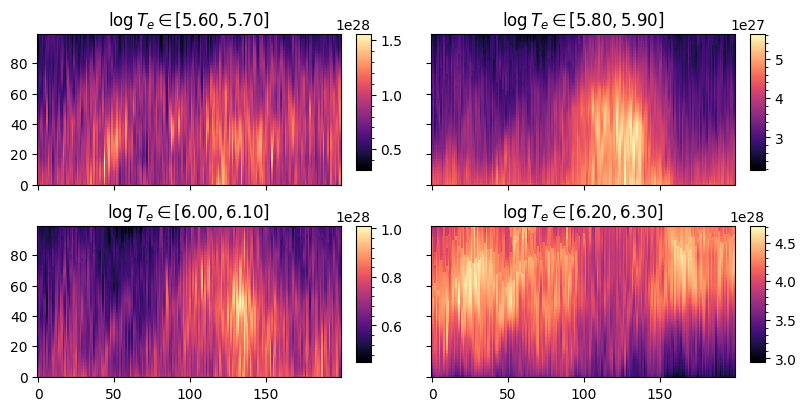

In [64]:
show_slit_dem(aia_df1_dem)

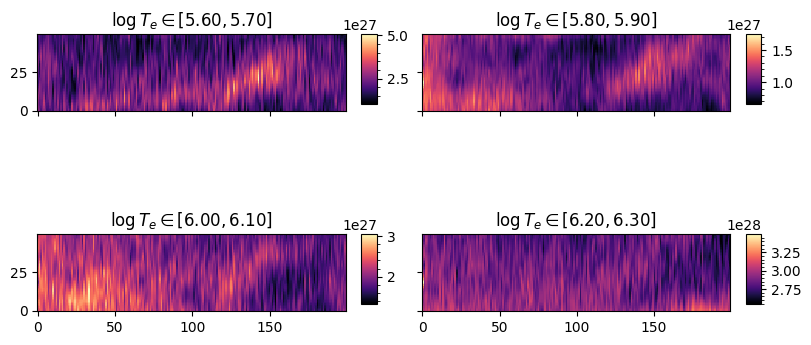

In [65]:
show_slit_dem(aia_df2_dem)

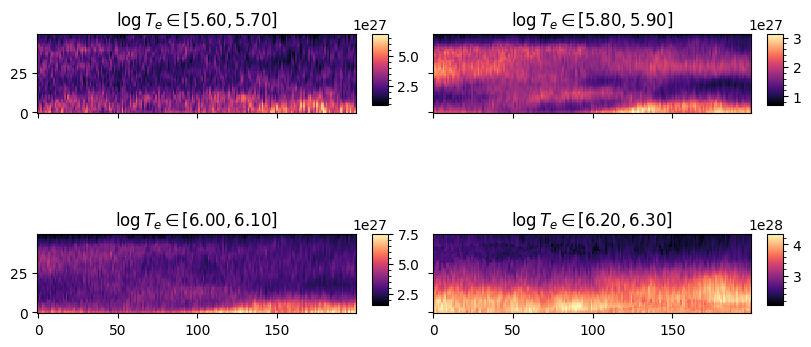

In [66]:
show_slit_dem(aia_df3_dem)

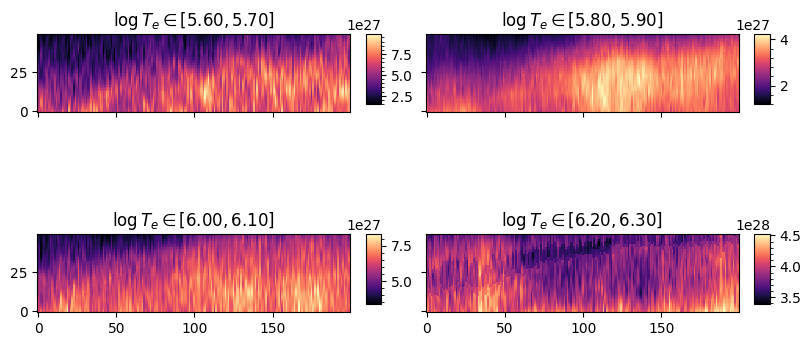

In [67]:
show_slit_dem(aia_df4_dem)

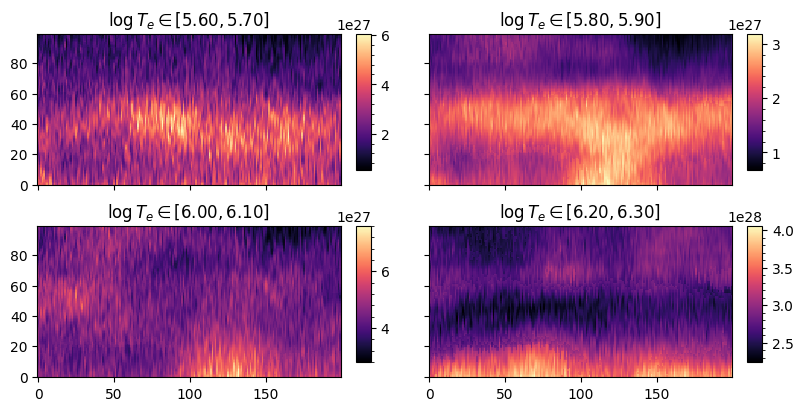

In [68]:
show_slit_dem(aia_ef1_dem)

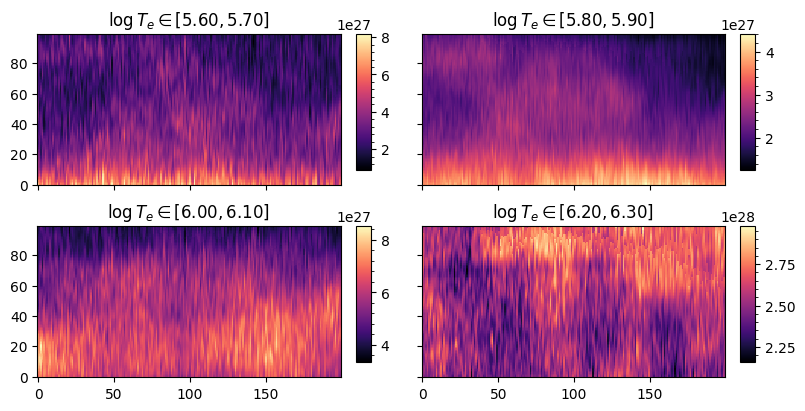

In [69]:
show_slit_dem(aia_ef2_dem)

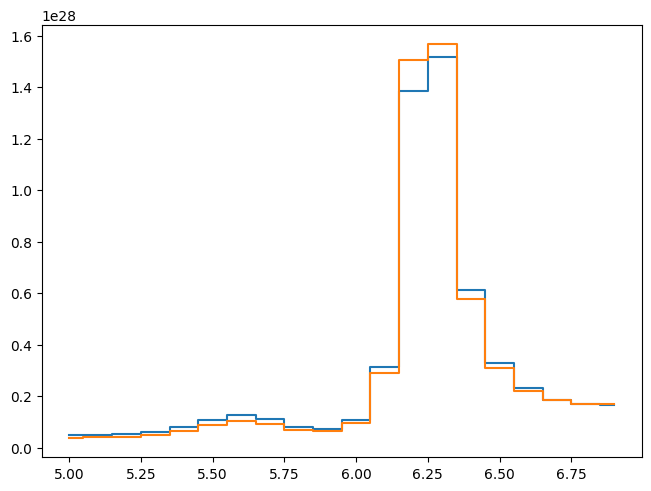

In [52]:
fig, ax = plt.subplots(layout="constrained")
ax.step(logte, aia_ef1_dem[70, 140], where="mid")
ax.step(logte, aia_ef1_dem[70, 150], where="mid")

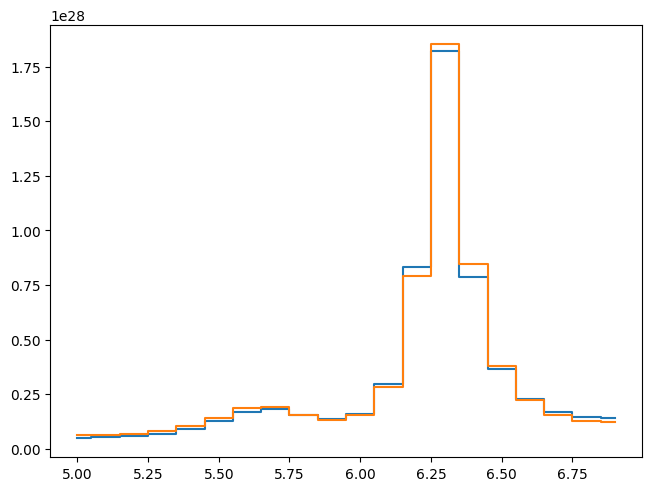

In [53]:
fig, ax = plt.subplots(layout="constrained")
ax.step(logte, aia_ef1_dem[40, 159], where="mid")
ax.step(logte, aia_ef1_dem[40, 145], where="mid")